In [26]:
#import necessary libraries
from pytesseract import Output
import pytesseract
import argparse
import imutils
from PIL import Image
import numpy as np
import cv2


In [46]:
# Specify the path to the Tesseract executable
pytesseract.pytesseract.tesseract_cmd = '/opt/homebrew/opt/tesseract/bin/tesseract'

def deskew(image):
    """Correct image skew using OpenCV's minAreaRect method"""
    # Convert PIL Image to OpenCV format (RGB)
    image_original = np.array(image)
    image_rgb = np.array(image)

    # Convert to grayscale and threshold
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Find all non-zero points in the thresholded image
    points = np.column_stack(np.where(thresh.transpose() > 0))

    # Get minimum area rectangle and angle
    rect = cv2.minAreaRect(points)
    angle = rect[-1]

    # Adjust angle based on OpenCV's coordinate system
    if angle < -45:
        angle = 90 + angle
    else:
        angle = -angle

    # Only rotate if significant angle is detected
    (h, w) = image_rgb.shape[:2]
    center = (w // 2, h // 2)
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)  # Invert the angle
    deskewed = cv2.warpAffine(image_original, matrix, (w, h),
                            flags=cv2.INTER_CUBIC,
                            borderMode=cv2.BORDER_CONSTANT)
    return Image.fromarray(deskewed)
    


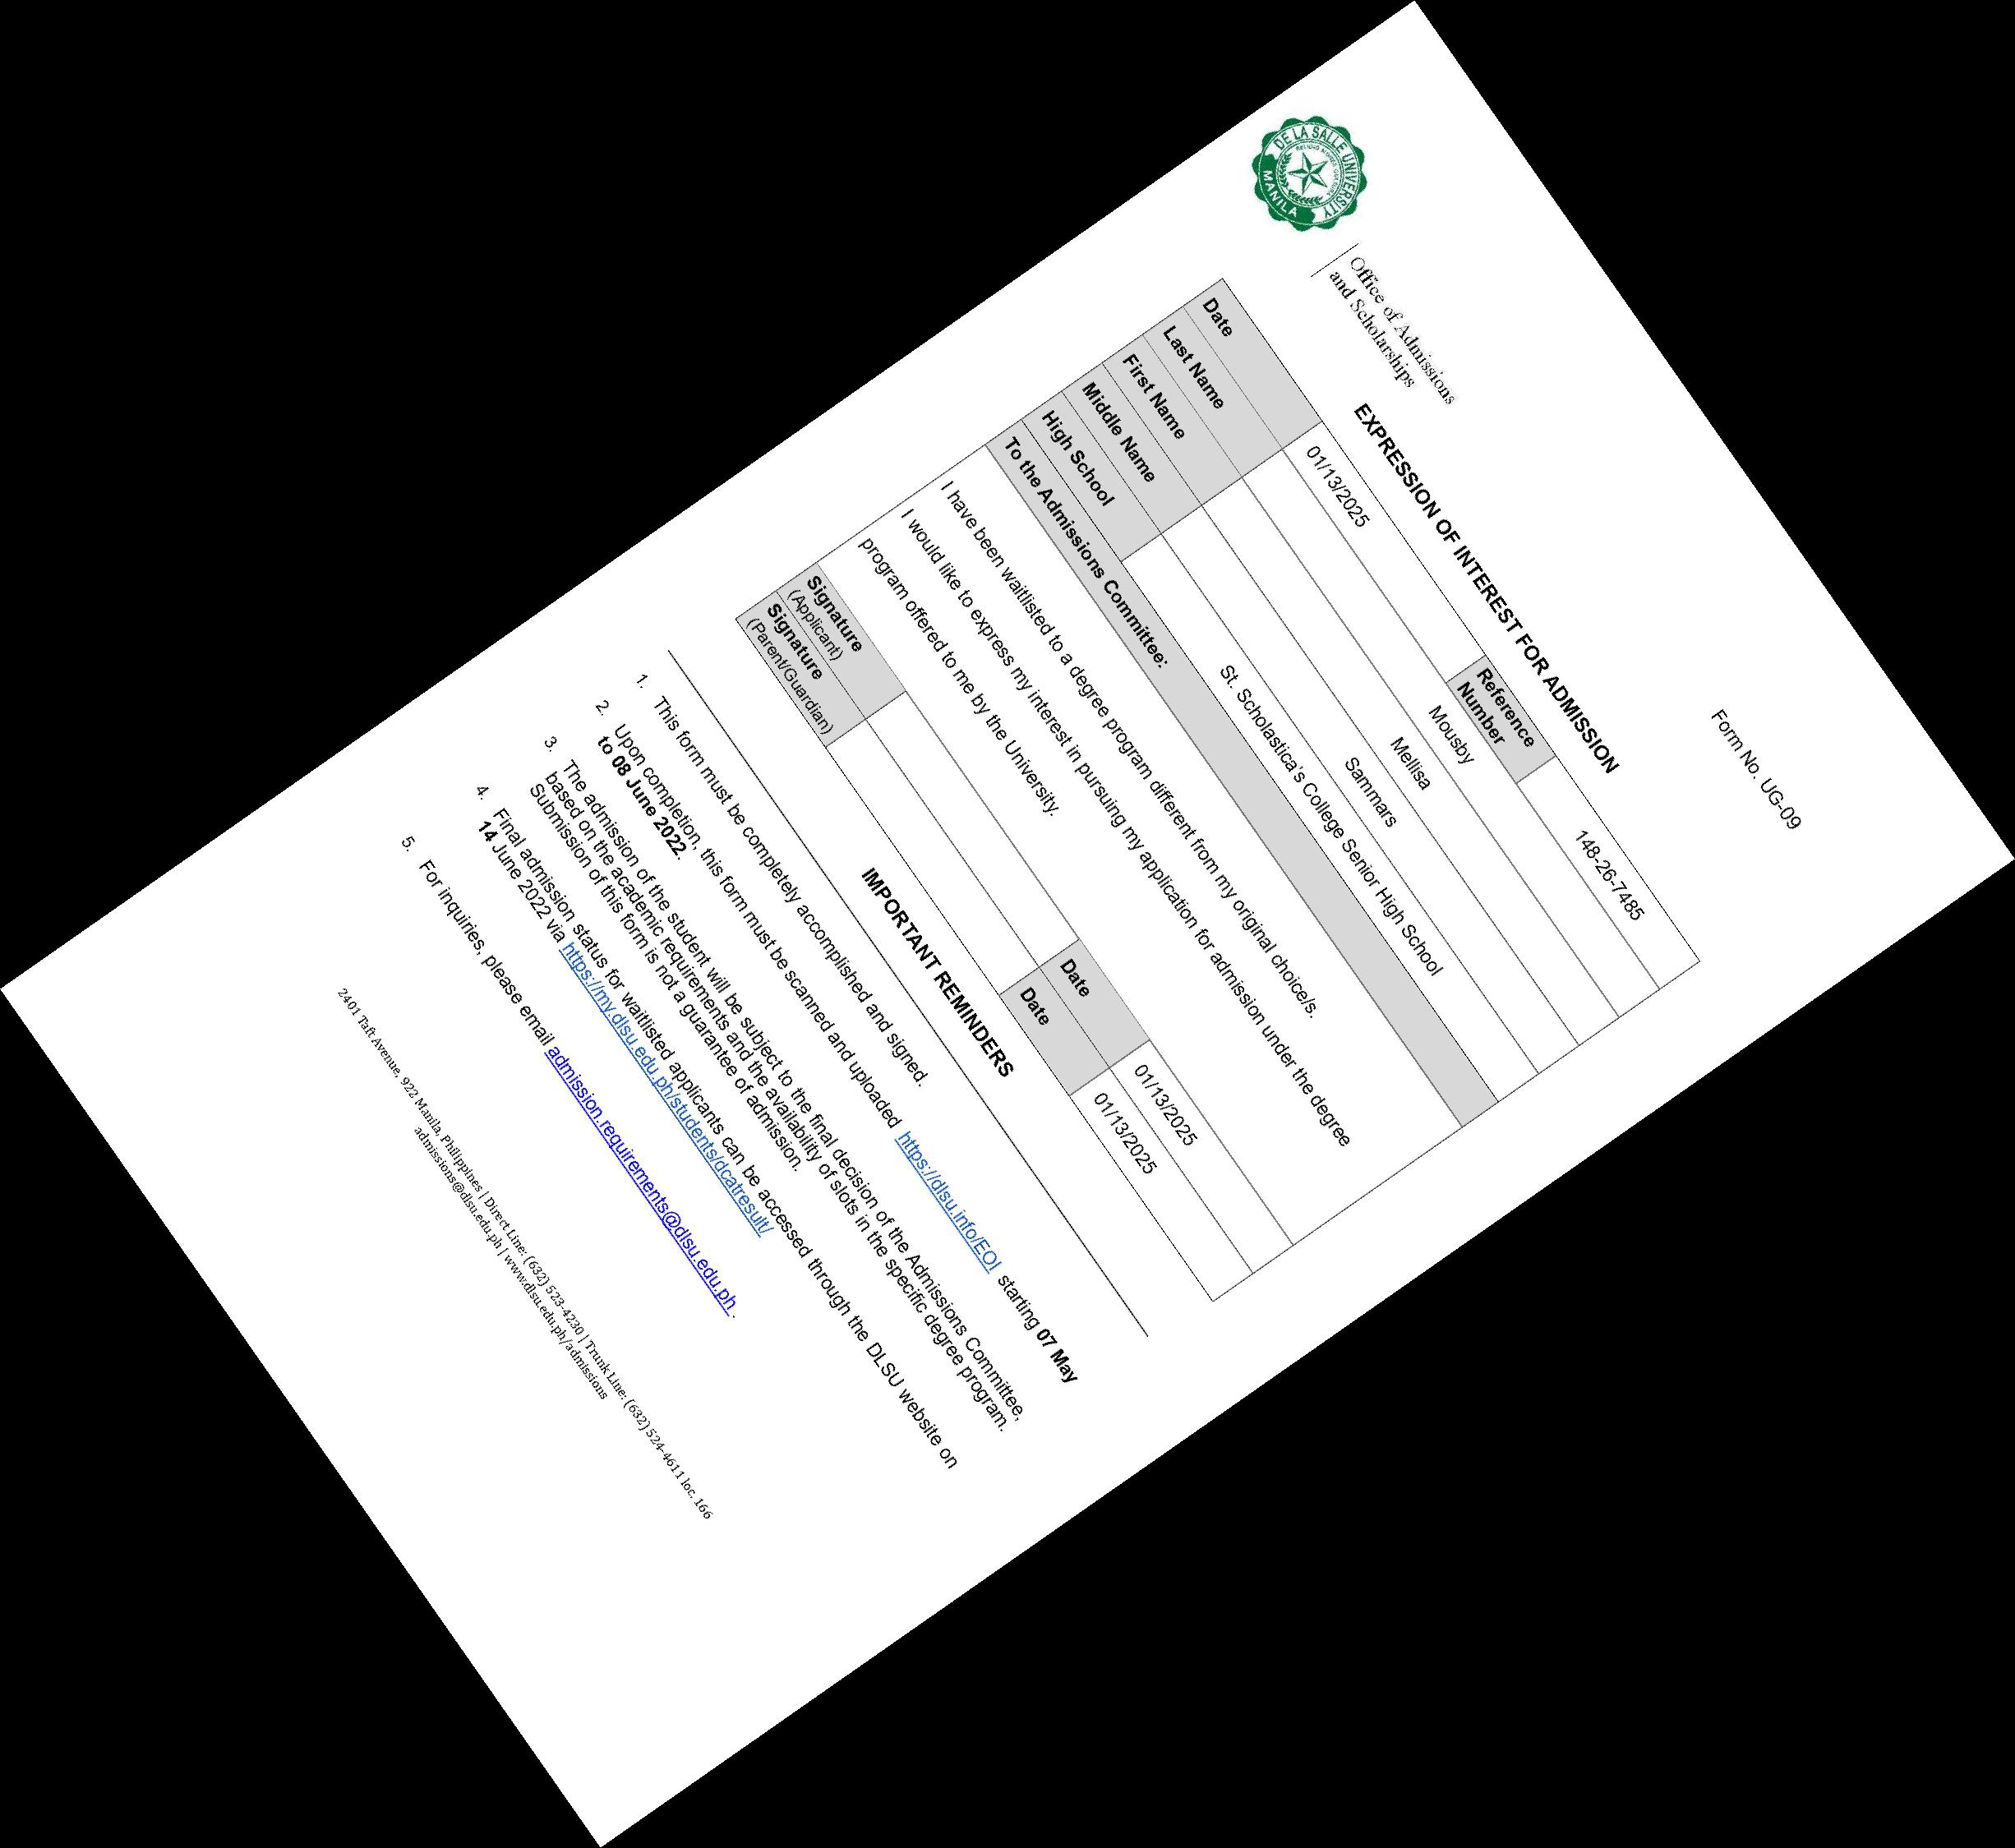

In [47]:
# Open an image file
imageFile = Image.open('Mail Merged Forms with Effects/form page 1-rotate-001.jpg')
display(imageFile)

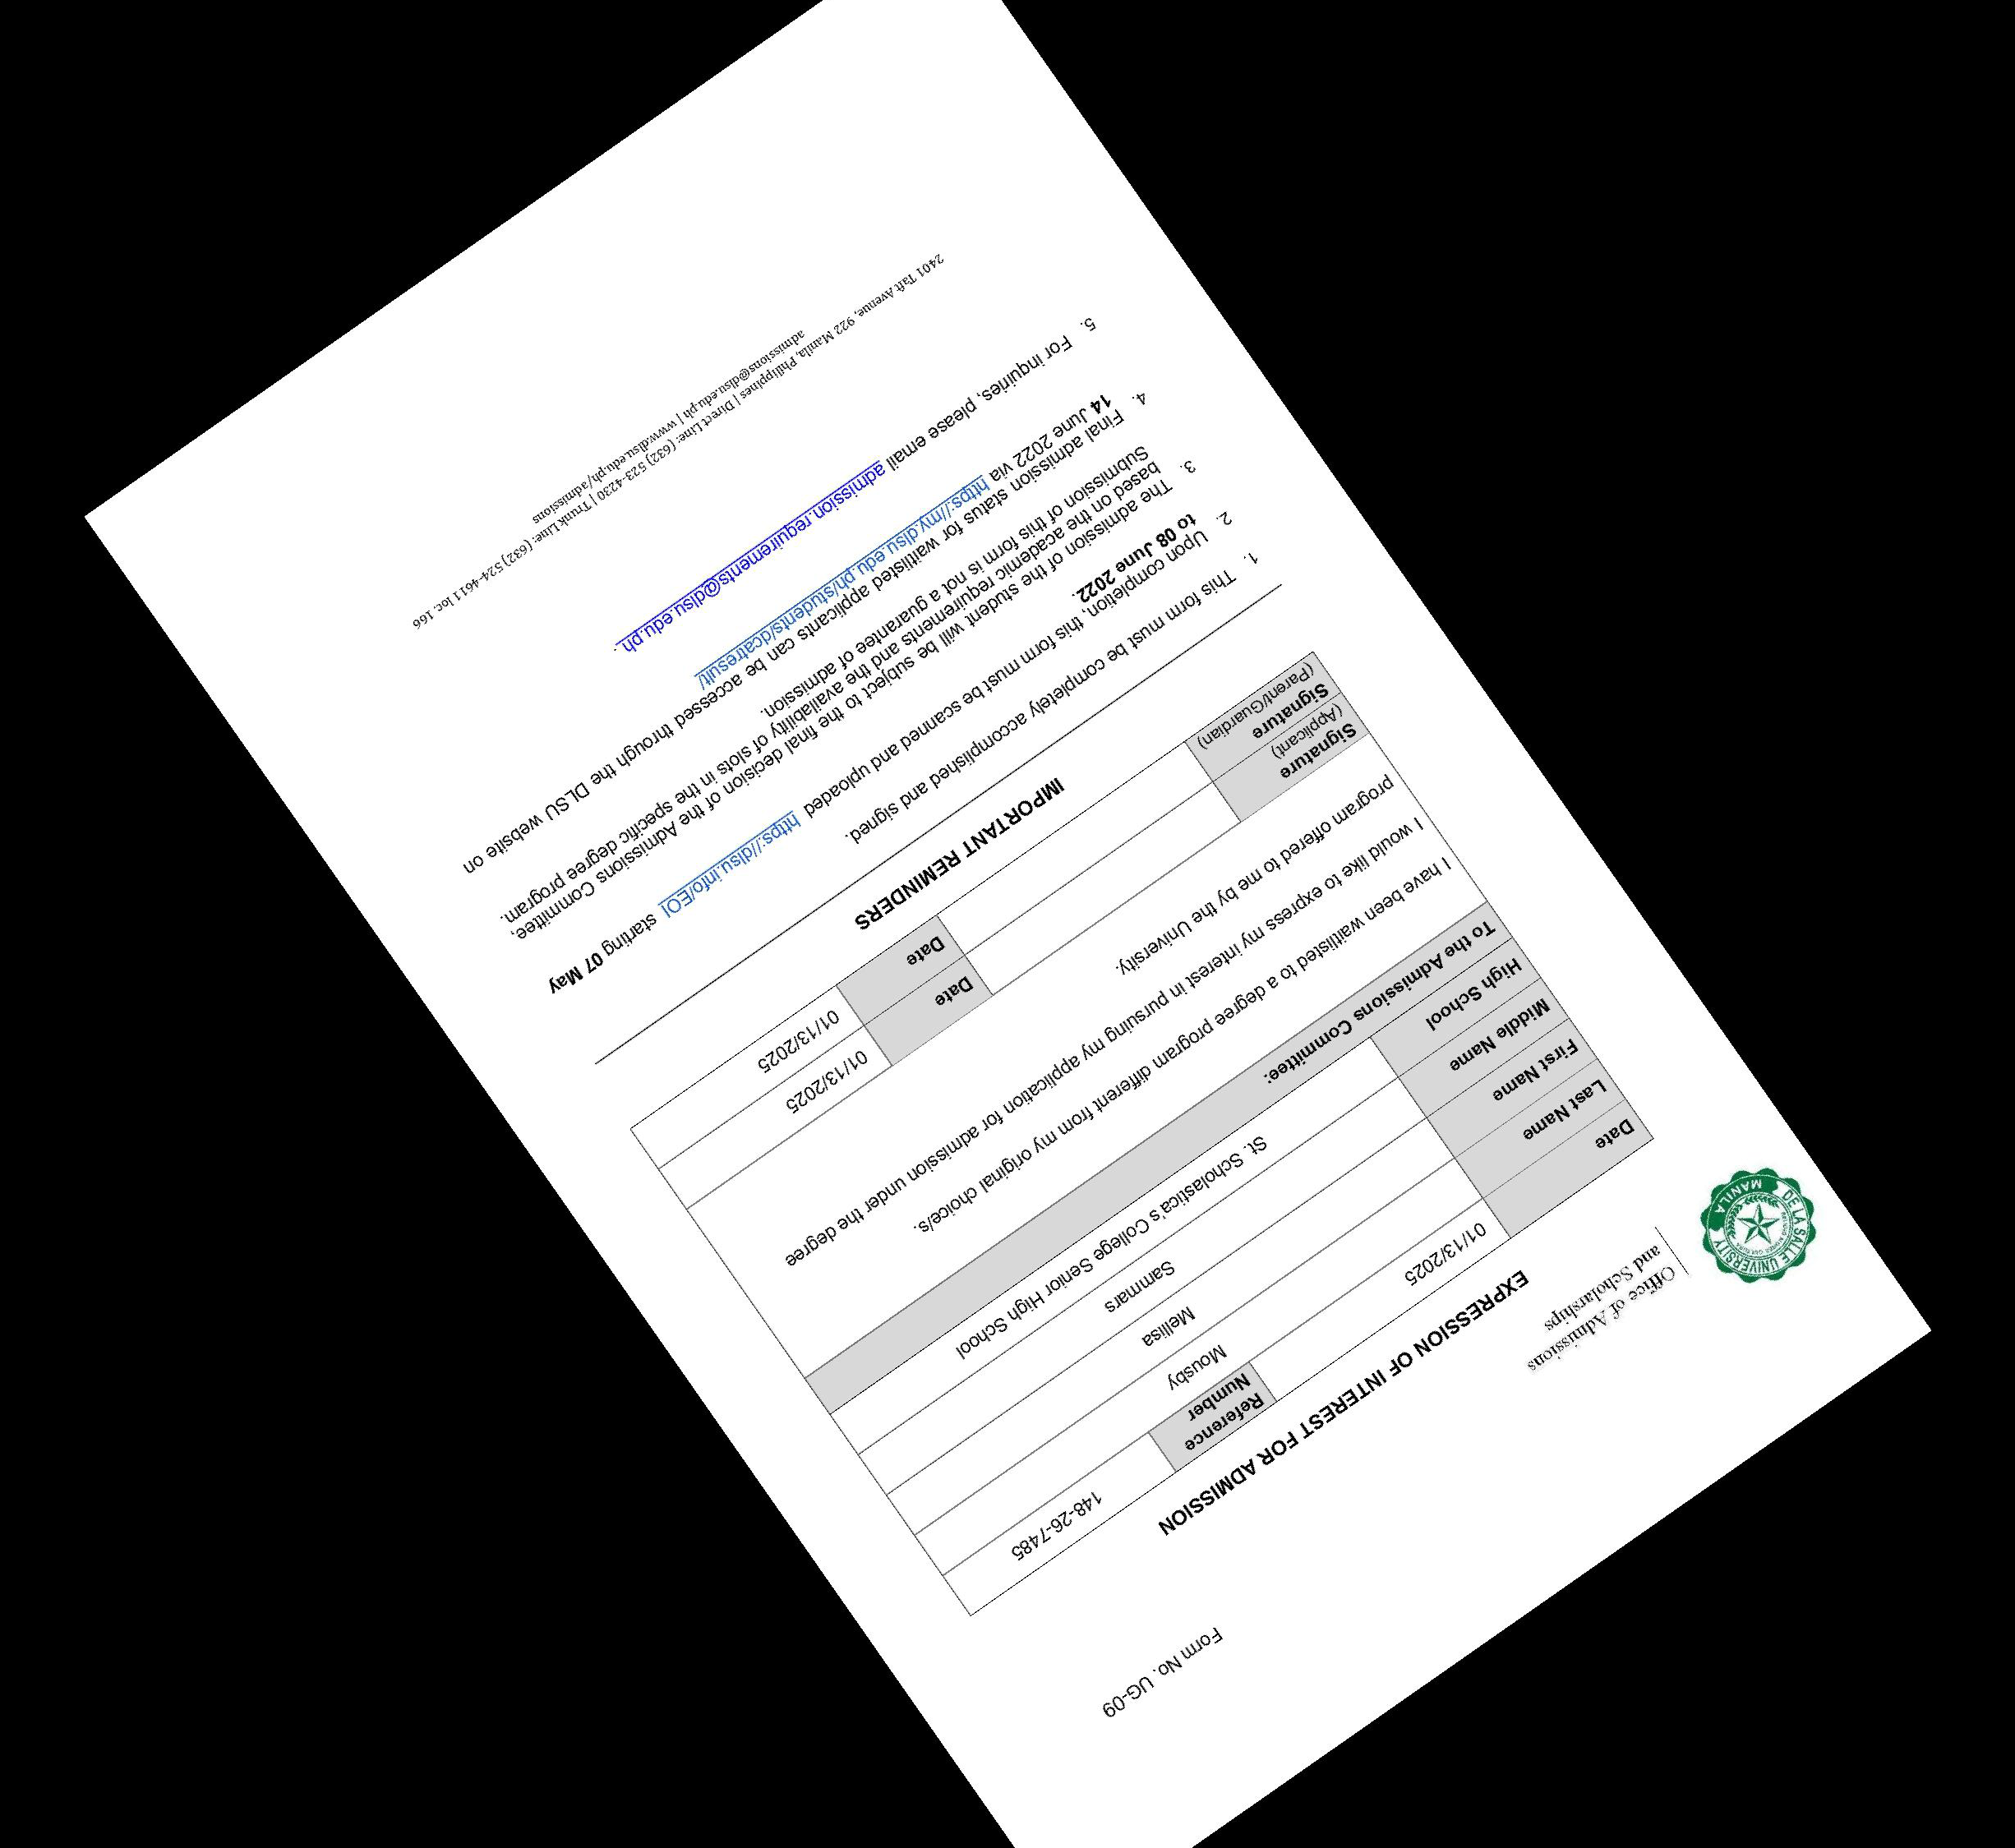

In [51]:
deskewed_image = deskew(imageFile)
display(deskewed_image)

In [38]:
# Define bounding box
bbox_imageFile = (500, 0, deskewed_image.size[0], 1000)

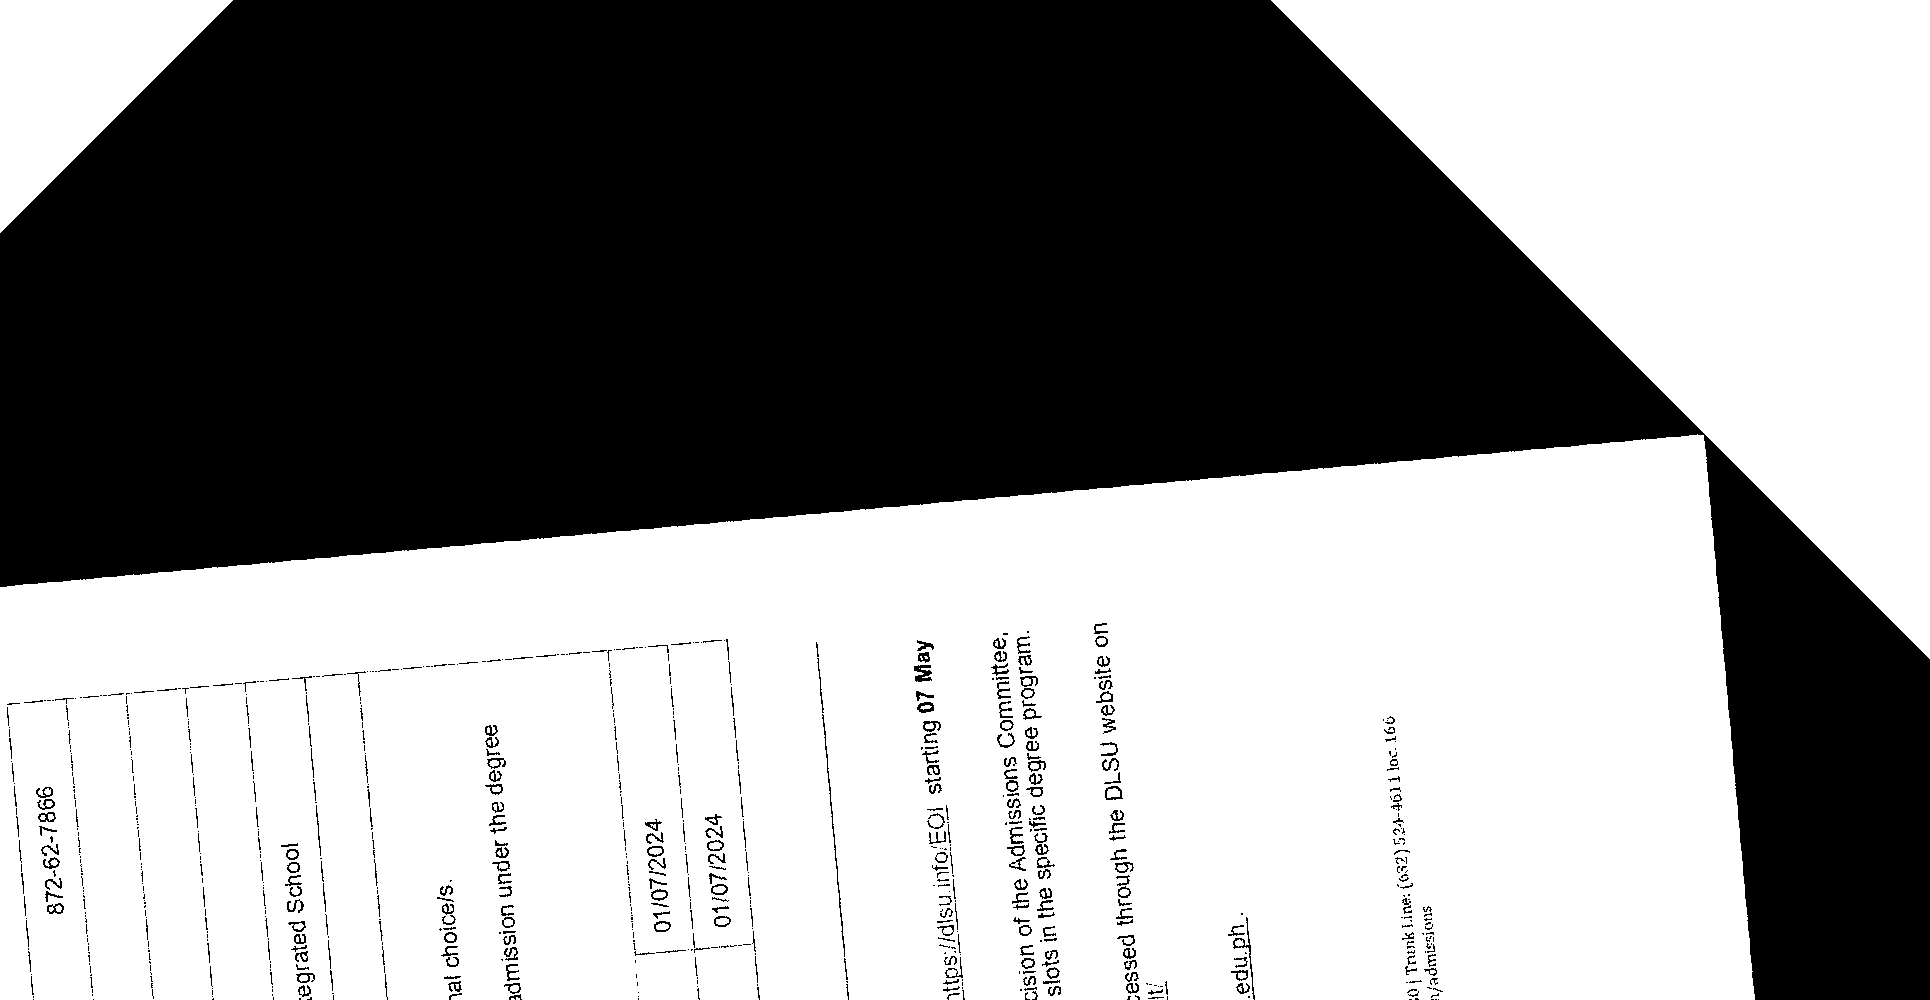

In [36]:
cropped_image = deskewed_image.crop(bbox_imageFile)
display(deskewed_image.crop(bbox_imageFile))

In [39]:
text = pytesseract.image_to_string(cropped_image)
print(text)

uo aysqem 1

“wiel6osd gaibep out

Qgy 2 Tae es

SIG 3ut yGnosy} PEs

Rew 29 Suivers | 5a

pzouZoio

gaibep au} Japun yols'

yoouss payes6

(ge

YeTpS

pads au) ul SIOIS

‘gayWUuWwod euoissiuipy ay 40 UCISE

aur TSPF SAM

\
—_—

SUPE

“gfanjoud {el


